In [22]:
import shutil
import sys
from pathlib import Path

BASE1 = Path("/nfs/team361/sb75/nichejepa-reproducibility/artifacts")
BASE2 = Path("/nfs/team361/sb75/nichejepa-reproducibility/artifacts")

def copy_model_files(model_timestamp: str):
    src_dir = BASE1 / "mmb0-1b_smb1-1b_2p_coord_aligned" / model_timestamp
    tgt_dir = BASE2 / "models" / model_timestamp
    token_src = BASE2 / "models" / "26032026_110730_071" / "token_dictionary.pkl"

    tgt_dir.mkdir(parents=True, exist_ok=True)

    copies = [
        (src_dir / "nichejepa-latest.pth.tar", tgt_dir / "model_checkpoint.pt"),
        (src_dir / "params.yaml",           tgt_dir / "model_config.yaml"),
        (token_src,                         tgt_dir / "token_dictionary.pkl"),
    ]

    for src, tgt in copies:
        print(f"Copying {src} -> {tgt}")
        shutil.copy2(src, tgt)

    print("Done.")

if __name__ == "__main__":
    ts = "22042026_132756_159"
    copy_model_files(ts)

Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p_coord_aligned/22042026_132756_159/nichejepa-latest.pth.tar -> /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/22042026_132756_159/model_checkpoint.pt
Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p_coord_aligned/22042026_132756_159/params.yaml -> /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/22042026_132756_159/model_config.yaml
Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/26032026_110730_071/token_dictionary.pkl -> /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/22042026_132756_159/token_dictionary.pkl
Done.


In [11]:
import scanpy as sc
adata_coord_aligned = sc.read_h5ad('/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p_coord_aligned/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

In [12]:
adata = sc.read_h5ad('/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

In [13]:
adata_coord_aligned

AnnData object with n_obs × n_vars = 42136 × 431
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type', 'cell_type_ontology_term_id', 'n_genes', 'cell_id', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'sex', 'spatial_neighbors', 'species', 'study', 'tissue'
    obsm: 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [14]:
adata

AnnData object with n_obs × n_vars = 42136 × 431
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type', 'cell_type_ontology_term_id', 'n_genes', 'cell_id', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'sex', 'spatial_neighbors', 'species', 'study', 'tissue'
    obsm: 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [21]:
import numpy as np
from scipy import sparse

# Quick check that works for both dense and sparse
def arrays_equal(a, b):
    if a.shape != b.shape:
        return False
    if sparse.issparse(a) or sparse.issparse(b):
        # Convert both to the same format and compare
        diff = a - b
        return diff.nnz == 0 if sparse.issparse(diff) else not np.any(diff)
    return np.array_equal(a, b)

print(arrays_equal(adata.X, adata_coord_aligned.X))

True


/tmp/ipykernel_3677216/3111401196.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_coord_aligned, spot_size=30, color='nichecompass_latent_cluster')


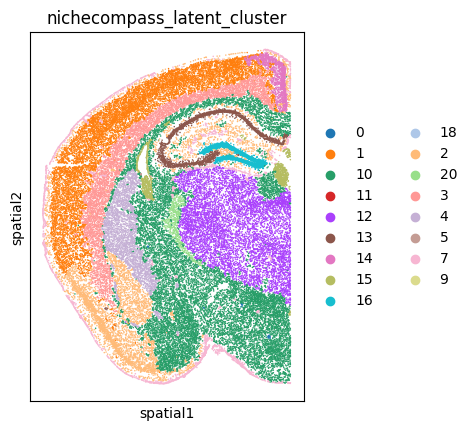

In [19]:
sc.pl.spatial(adata_coord_aligned, spot_size=30, color='nichecompass_latent_cluster')

/tmp/ipykernel_3677216/376165289.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, spot_size=100, color='nichecompass_latent_cluster')


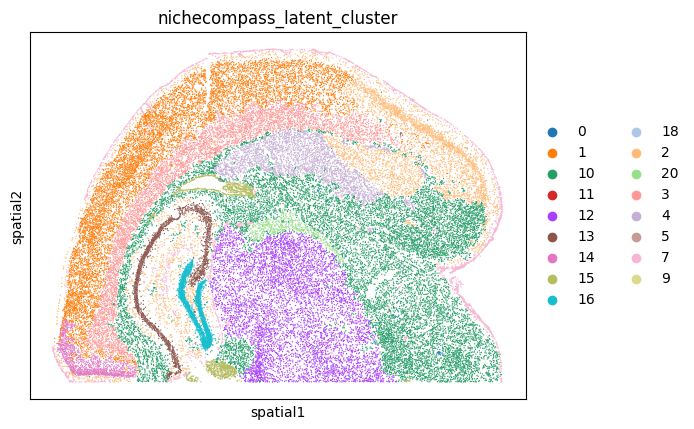

In [20]:
sc.pl.spatial(adata, spot_size=100, color='nichecompass_latent_cluster')